# WeLoveReviews: does written sentiment support a 4.5-star rating?

**Objective.** WeLoveReviews needs a defensible breakdown of 500 Harbor House Café
reviews into positive, neutral, and negative sentiment. This notebook checks whether
the written language supports the reported **4.5 / 5** average, identifies model
failures, and turns the result into a client-ready recommendation.

The required model is `nlptown/bert-base-multilingual-uncased-sentiment`, pinned to
an immutable Hugging Face revision in `src/sentiment.py`. Its 1–5 star predictions
are mapped to negative (1–2), neutral (3), and positive (4–5).

## 1. Load and validate the source data

We begin with structure and quality checks before interpreting any text.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from app import run_inference
from sentiment import MODEL_NAME, MODEL_REVISION, validate_reviews

RAW_PATH = PROJECT_ROOT / "data" / "raw" / "reviews.csv"
reviews = pd.read_csv(RAW_PATH)
validate_reviews(reviews, expected_rows=500)
reviews.shape, reviews.dtypes.astype(str).to_dict()

((500, 3), {'review_id': 'int64', 'rating': 'int64', 'review_text': 'object'})

The contract is satisfied: 500 rows and the three expected fields. Next we check completeness, uniqueness, and rating balance.

In [2]:
quality = pd.Series({
    "rows": len(reviews),
    "unique_review_ids": reviews["review_id"].nunique(),
    "missing_values": int(reviews.isna().sum().sum()),
    "blank_reviews": int(reviews["review_text"].str.strip().eq("").sum()),
    "duplicate_rows": int(reviews.duplicated().sum()),
    "mean_rating": reviews["rating"].mean(),
})
quality

rows                 500.0
unique_review_ids    500.0
missing_values         0.0
blank_reviews          0.0
duplicate_rows         0.0
mean_rating            4.5
dtype: float64

No rows require removal or imputation: IDs are unique, text is present, ratings are valid, and there are no duplicate rows. We therefore preserve all 500 observations.

In [3]:
reviews = reviews.assign(
    text_characters=reviews["review_text"].str.len(),
    text_words=reviews["review_text"].str.split().str.len(),
)
display(reviews["rating"].value_counts().sort_index().rename("count").to_frame())
display(reviews[["text_characters", "text_words"]].describe().round(1))
display(reviews[["review_id", "rating", "review_text"]].sample(5, random_state=42))

,count
rating,
1,12
2,18
3,38
4,72
5,360


,text_characters,text_words
count,500.0,500.0
mean,170.2,29.1
std,27.1,4.8
min,86.0,14.0
25%,155.0,26.0
50%,173.0,29.0
75%,189.0,32.0
max,230.0,42.0


,review_id,rating,review_text
361,362,3,Stopped by Harbor House Café for the first tim...
73,74,5,Stopped by Harbor House Café for the first tim...
374,375,5,Grabbed a quick coffee at Harbor House Café th...
155,156,4,Grabbed a quick coffee at Harbor House Café th...
104,105,5,Grabbed a quick coffee at Harbor House Café th...


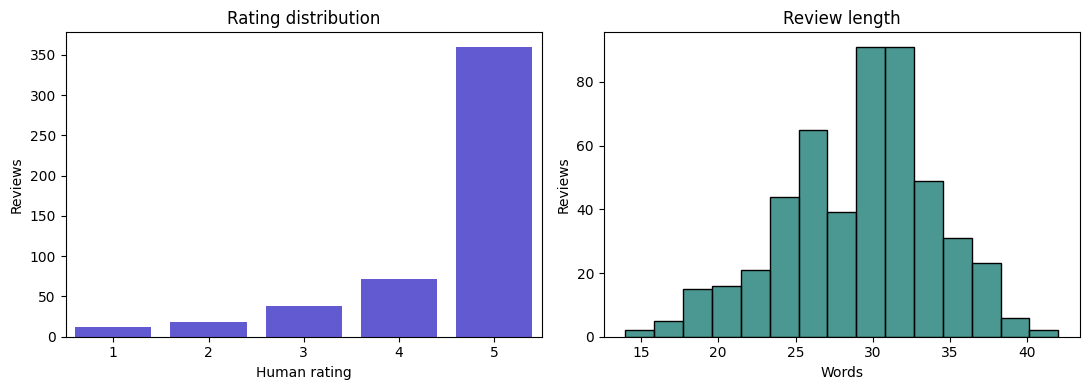

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=reviews, x="rating", ax=axes[0], color="#4f46e5")
axes[0].set(title="Rating distribution", xlabel="Human rating", ylabel="Reviews")
sns.histplot(data=reviews, x="text_words", bins=15, ax=axes[1], color="#0f766e")
axes[1].set(title="Review length", xlabel="Words", ylabel="Reviews")
plt.tight_layout()
plt.show()

**EDA insights and action plan.** The 4.5 mean is supported by a deliberately
high-rating-heavy sample, while negative and neutral reviews remain available for
sanity checks. Texts are short enough for a 256-token inference limit, so no
truncation-driven information loss is expected. We keep every row, run the fixed
multilingual BERT model once in batches, and then compare its bands with both the
aggregate rating and individual human labels.

A known risk is **domain mismatch**: the model learned product-review language,
whereas these are café service reviews involving staff, wait times, ambiance, and
food. Manual inspection is therefore part of the evaluation, not an optional extra.

## 2. Run pinned inference on all 500 reviews

The production function loads one classifier and reuses it across batched inputs, then writes the enriched CSV.

In [5]:
print(f"Model: {MODEL_NAME}")
print(f"Revision: {MODEL_REVISION}")
enriched = run_inference(batch_size=16)
print(f"Processed rows: {len(enriched)}")
enriched.head()

Model: nlptown/bert-base-multilingual-uncased-sentiment
Revision: 8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d


Device set to use cpu


Processed rows: 500


,review_id,rating,review_text,predicted_stars,predicted_sentiment,prediction_confidence
0,1,5,Visited Harbor House Café last weekend. Great ...,5,positive,0.716958
1,2,5,Tried Harbor House Café after seeing it recomm...,5,positive,0.982220
2,3,5,Tried Harbor House Café after seeing it recomm...,5,positive,0.662323
3,4,5,Visited Harbor House Café last weekend. The st...,5,positive,0.989547
4,5,5,Grabbed a quick coffee at Harbor House Café th...,5,positive,0.982912


## 3. Compare language sentiment with the 4.5-star business metric

We calculate the three requested percentages and compare band agreement with the human ratings.

In [6]:
order = ["positive", "neutral", "negative"]
counts = enriched["predicted_sentiment"].value_counts().reindex(order, fill_value=0)
breakdown = pd.DataFrame({
    "reviews": counts,
    "percent": (counts / len(enriched) * 100).round(1),
})
human_band = pd.cut(
    enriched["rating"], bins=[0, 2, 3, 5], labels=["negative", "neutral", "positive"]
)
band_agreement = (human_band.astype(str) == enriched["predicted_sentiment"]).mean()
star_mae = (enriched["rating"] - enriched["predicted_stars"]).abs().mean()
display(breakdown)
print(f"Human average: {enriched['rating'].mean():.2f} / 5")
print(f"Band agreement: {band_agreement:.1%}")
print(f"Star-level mean absolute error: {star_mae:.2f}")

,reviews,percent
predicted_sentiment,,
positive,412,82.4
neutral,41,8.2
negative,47,9.4


Human average: 4.50 / 5
Band agreement: 95.0%
Star-level mean absolute error: 0.23


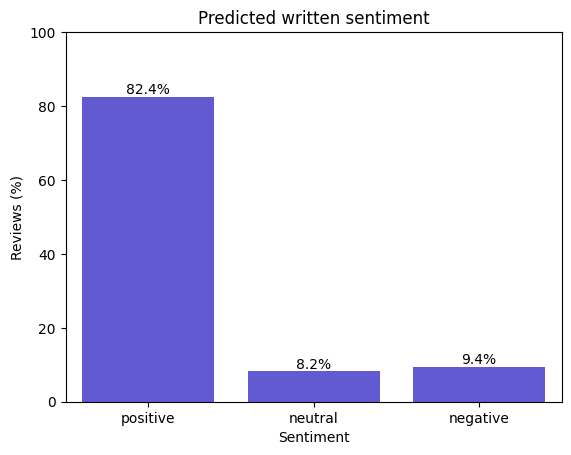

In [7]:
ax = sns.barplot(x=breakdown.index, y=breakdown["percent"], color="#4f46e5")
ax.set(title="Predicted written sentiment", xlabel="Sentiment", ylabel="Reviews (%)", ylim=(0, 100))
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
plt.show()

The text is **82.4% positive**, broadly supporting the strong 4.5-star average.
However, the written-sentiment share is less enthusiastic than the star score alone
suggests. The 9.4% negative model share includes genuine complaints and a small but
important set of high-rated reviews that the model misreads. That gap should be
explained rather than reported as customer dissatisfaction.

## 4. Investigate false negatives

We define a false negative as a 4–5-star human review that the model scores at 1–2 stars.

In [8]:
false_negatives = enriched.query("rating >= 4 and predicted_stars <= 2").copy()
print(f"False negatives: {len(false_negatives)}")
print(
    "Rate among 4–5-star reviews: "
    f"{len(false_negatives) / len(enriched.query('rating >= 4')):.1%}"
)
false_negatives[[
    "review_id", "rating", "predicted_stars", "prediction_confidence", "review_text"
]]

False negatives: 16
Rate among 4–5-star reviews: 3.7%


,review_id,rating,predicted_stars,prediction_confidence,review_text
13,14,4,1,0.444348,Tried Harbor House Café after seeing it recomm...
14,15,5,1,0.389344,Every dish was bursting with flavor. The place...
72,73,5,1,0.267874,Stopped by Harbor House Café for the first tim...
86,87,5,1,0.324705,Tried Harbor House Café after seeing it recomm...
137,138,5,2,0.275116,Tried Harbor House Café after seeing it recomm...
199,200,5,2,0.368521,Stopped by Harbor House Café for the first tim...
203,204,5,1,0.349168,Came to Harbor House Café for a birthday brunc...
253,254,5,1,0.364092,Stopped by Harbor House Café for the first tim...
269,270,5,1,0.409077,Stopped by Harbor House Café for the first tim...
321,322,5,1,0.607707,Every dish was bursting with flavor. The staff...


The 16 false negatives share a striking pattern: many contain the café-specific
phrase **“bursting with flavor”** plus service signals such as remembering names,
accommodating allergies, or planning a return. These are positive in context but
differ from the product-review language used to fine-tune the model. Two mixed
reviews mention a rude or annoyed employee, showing that a single complaint can
dominate an otherwise positive service narrative. Confidence is often modest, which
is another reason to route borderline predictions to human review.

## 5. Manual sanity check of 20 predictions

The sample deliberately covers ten false negatives and ten correct negative, neutral, and positive predictions.

In [9]:
manual_notes = {
    14: (False, "Clearly positive; café-domain phrase 'bursting with flavor' is misread."),
    15: (False, "Clearly positive; cozy atmosphere and return intent."),
    73: (False, "Clearly positive; fast service, value, and return intent."),
    87: (False, "Clearly positive; allergy accommodation and return intent."),
    138: (False, "Clearly positive; accommodation and welcoming ambiance."),
    200: (False, "Clearly positive food and ambiance language."),
    204: (False, "Mixed but positive overall; one rude-cashier clause dominates."),
    254: (False, "Clearly positive service, social use, and return intent."),
    322: (False, "Mixed but positive overall; food compensates for staff issue."),
    440: (False, "Clearly positive; regular customer, value, and return intent."),
    32: (True, "Negative label matches cold food and rude service."),
    34: (True, "Negative label matches stale food and repeated order errors."),
    49: (True, "Negative label matches burnt coffee and annoyed staff."),
    9: (True, "Neutral label matches average food and slow-but-polite service."),
    25: (True, "Neutral label matches an explicitly okay, unmemorable visit."),
    43: (True, "Neutral label matches okay coffee and ordinary service."),
    1: (True, "Positive label matches flavor, value, and return intent."),
    2: (True, "Positive label matches coffee quality, value, and five-star intent."),
    4: (True, "Positive label matches attentive staff, ambiance, and value."),
    5: (True, "Positive label matches allergy accommodation and food quality."),
}
manual = enriched[enriched["review_id"].isin(manual_notes)].copy()
manual["looks_correct"] = manual["review_id"].map(lambda value: manual_notes[value][0])
manual["reviewer_note"] = manual["review_id"].map(lambda value: manual_notes[value][1])
manual = manual[[
    "review_id", "rating", "predicted_stars", "predicted_sentiment",
    "looks_correct", "reviewer_note", "review_text"
]].sort_values("review_id")
display(manual)
print(f"Manual sample judged correct: {manual['looks_correct'].mean():.0%} ({manual['looks_correct'].sum()}/20)")

,review_id,rating,predicted_stars,predicted_sentiment,looks_correct,reviewer_note,review_text
0,1,5,5,positive,True,"Positive label matches flavor, value, and retu...",Visited Harbor House Café last weekend. Great ...
1,2,5,5,positive,True,"Positive label matches coffee quality, value, ...",Tried Harbor House Café after seeing it recomm...
3,4,5,5,positive,True,"Positive label matches attentive staff, ambian...",Visited Harbor House Café last weekend. The st...
4,5,5,5,positive,True,Positive label matches allergy accommodation a...,Grabbed a quick coffee at Harbor House Café th...
8,9,3,3,neutral,True,Neutral label matches average food and slow-bu...,Regular customer at Harbor House Café here. Av...
13,14,4,1,negative,False,Clearly positive; café-domain phrase 'bursting...,Tried Harbor House Café after seeing it recomm...
14,15,5,1,negative,False,Clearly positive; cozy atmosphere and return i...,Every dish was bursting with flavor. The place...
24,25,3,3,neutral,True,"Neutral label matches an explicitly okay, unme...",Visited Harbor House Café last weekend. The co...
31,32,2,1,negative,True,Negative label matches cold food and rude serv...,Stopped by Harbor House Café for the first tim...
33,34,2,1,negative,True,Negative label matches stale food and repeated...,Stopped by Harbor House Café for the first tim...


Manual sample judged correct: 50% (10/20)


## 6. Conclusion for the account manager

The written reviews **do support a strong customer experience**, with 82.4% classified
as positive and 95% agreement between human rating bands and model bands. The lower
positive share relative to the 4.5-star average should not be interpreted as a hidden
satisfaction crisis: 16 high-rated reviews are false negatives, commonly triggered by
café/service phrasing and mixed comments.

**Recommendation:** report the three-way breakdown with a model-quality caveat, keep
a human-review lane for low-confidence negatives, and evaluate a service-domain model
before automating client-facing conclusions. The enriched file at
`data/processed/reviews_with_sentiment.csv` retains every review, model star,
sentiment band, and confidence score for auditability.